## Chargement et Analyse exploratoire des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import math 

In [2]:
# read dataset as dataframe

df = pd.read_csv("../data/raw/student_mental_health.csv")
df.head(6)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium
5,STU0006,20,Female,4,6.8,18.6,NaN,8.5,11.8,High,7.0,3.9,NaN,Yes,Average,No,Medium


In [3]:
# columns of dataset 

df.columns.to_list()

['Student_ID',
 'Age',
 'Gender',
 'Year_of_Study',
 'Sleep_Hours',
 'Study_Hours_Per_Week',
 'GPA',
 'Social_Media_Hours',
 'Screen_Time_Hours',
 'Physical_Activity',
 'Financial_Stress',
 'Family_Support',
 'Attendance_Rate',
 'Part_Time_Job',
 'Diet_Quality',
 'Previous_Mental_Health_History',
 'Mental_Health_Risk']

In [4]:
# information about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [5]:
# dataset shape
df.shape

(2000, 17)

In [6]:
# Description of the dataset
print("#" * 40)

print("#" * 40)
df.describe().T


########################################
########################################


,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


In [7]:
# verify class balance
df['Mental_Health_Risk'].value_counts()

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

#### **Resume based on descriptive statistics**

- the 


In [8]:
df.isna().sum()

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

In [9]:
# check duplicated rows in the dataset
df.duplicated().sum()

np.int64(0)

#### Skewness 

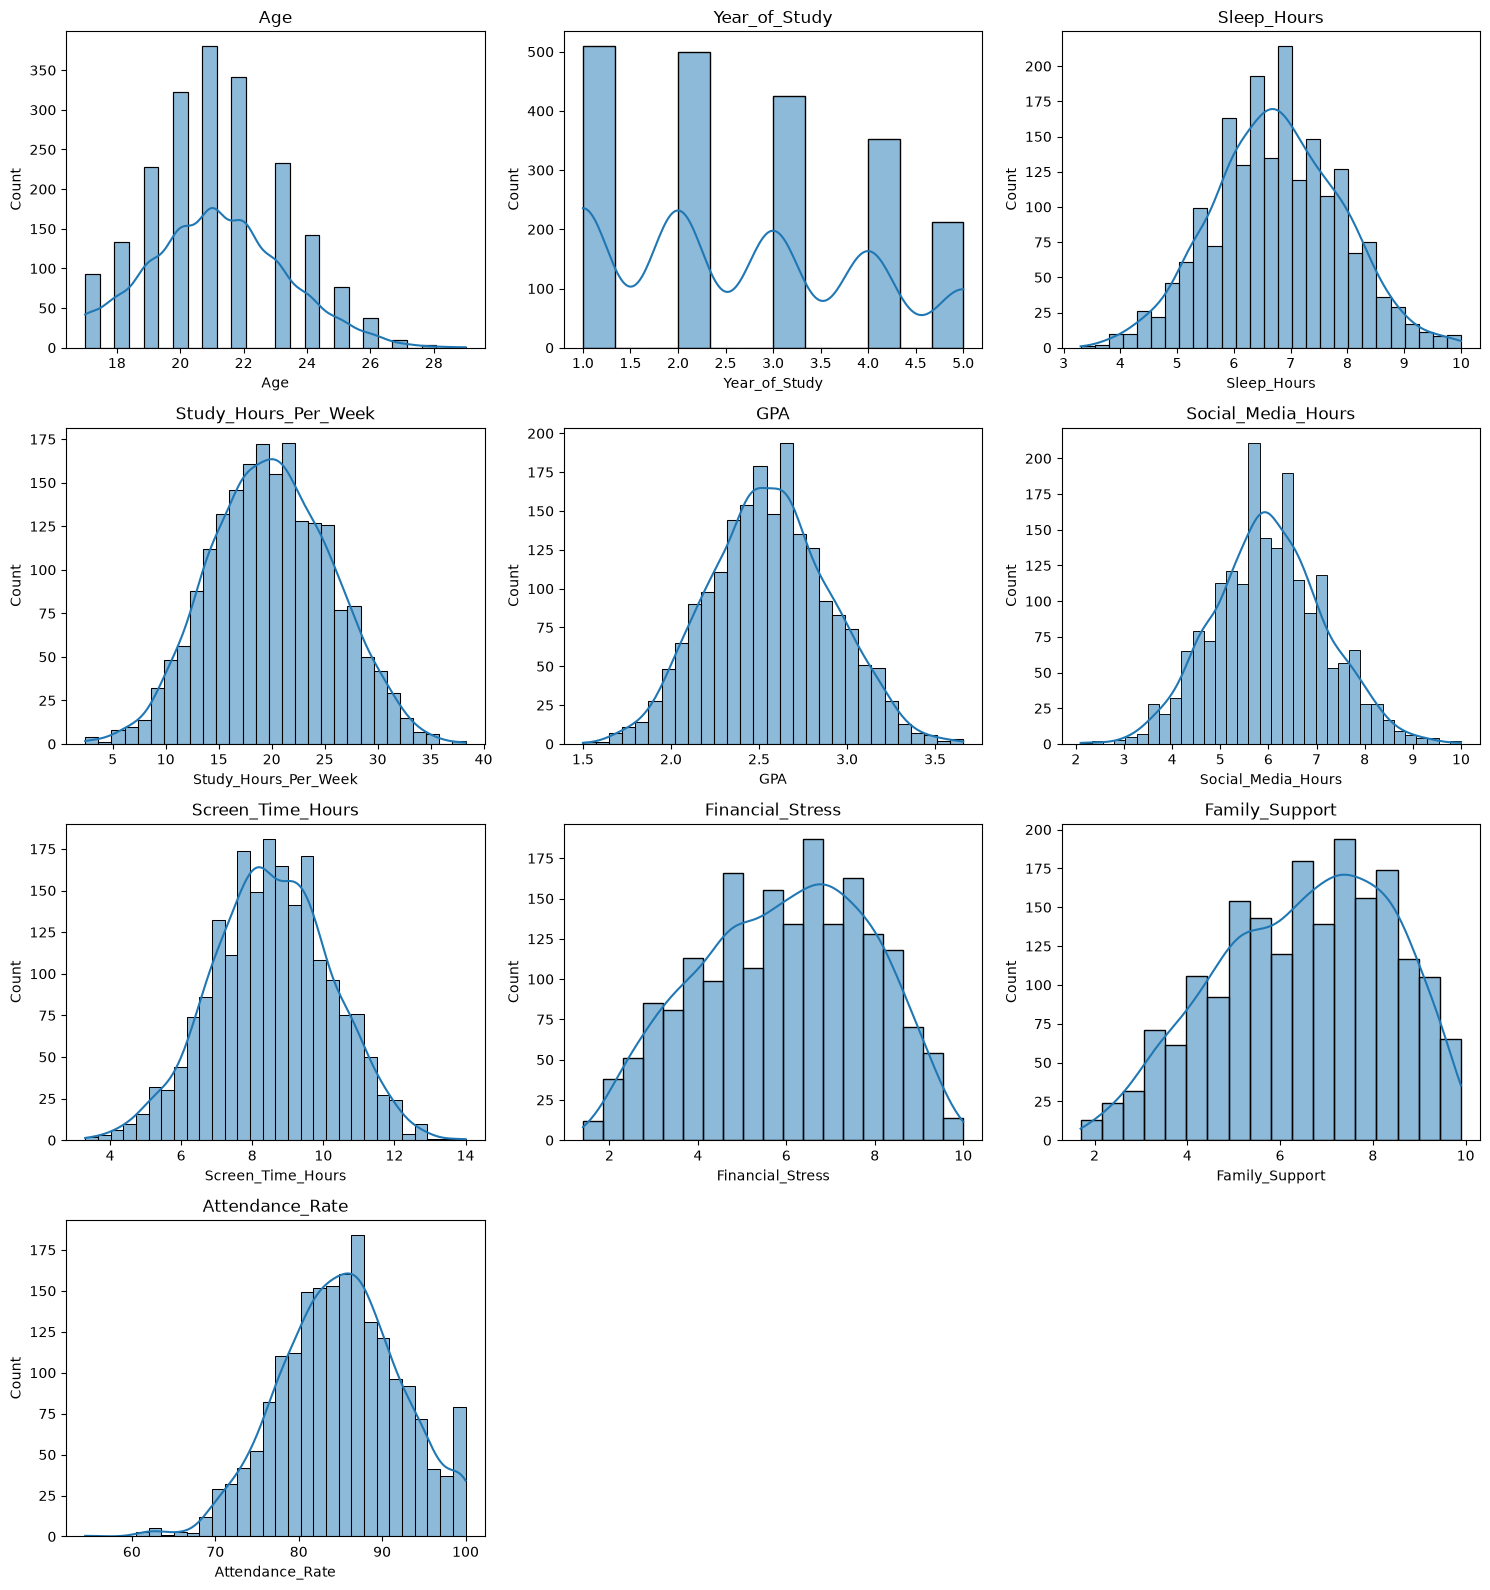

In [10]:
# visualize each column distribution include (symetric or skewness  )
num_cols = df.select_dtypes(include=["int", "float"]).columns
cols_per_row = 3
num_rows = math.ceil(len(num_cols) / cols_per_row)

fig, axes = plt.subplots(num_rows, cols_per_row, figsize=(15, 4 * num_rows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()


plt.show()


In [11]:
# skewness coificient

all_skewness = df.skew(numeric_only=True)

all_skewness


Age                     0.200876
Year_of_Study           0.314226
Sleep_Hours             0.051094
Study_Hours_Per_Week    0.039271
GPA                     0.087445
Social_Media_Hours      0.092598
Screen_Time_Hours      -0.044073
Financial_Stress       -0.168759
Family_Support         -0.304270
Attendance_Rate        -0.116483
dtype: float64

##### SKEWNESS COMPARISON METRICS
 
- -0.5 to 0.5: Fairly symmetrical data.
- -1.0 to -0.5 or 0.5 to 1.0: Moderate skewness.
- Less than -1.0 or Greater than 1.0: High/severe skewness.

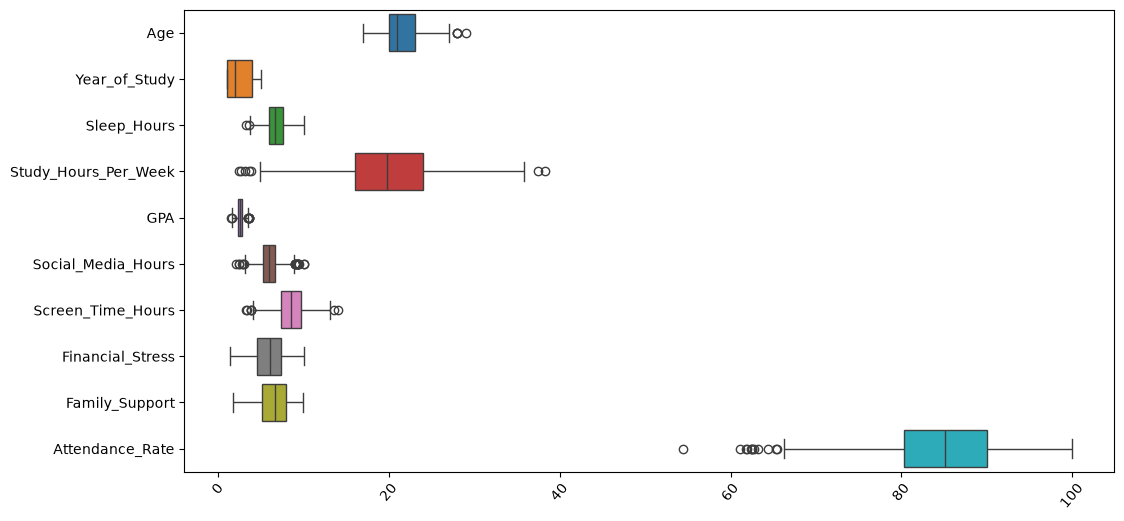

In [12]:
# Detecting outliers in the dataset using boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, orient="h")
plt.xticks(rotation=50)
plt.show()

In [ ]:
# Detecting outliers in the dataset using IQR method

numerical_cols = df.select_dtypes(include="number").columns

Q1 = df[numerical_cols].quantile(0.25)
Q3 = df[numerical_cols].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_mask= ((df[numerical_cols]  < lower_bound) | (df[numerical_cols] > upper_bound))



Age                      4
Year_of_Study            0
Sleep_Hours              2
Study_Hours_Per_Week     7
GPA                      9
Social_Media_Hours      20
Screen_Time_Hours        7
Financial_Stress         0
Family_Support           0
Attendance_Rate         12
dtype: int64

In [14]:
# show the outliers in each Feature detected using IQR method

for col in numerical_cols:
    values = df.loc[outliers_mask[col], col]

    if len(values) > 0:
        print(f"\n--- {col} ---")
        print(values.sort_values().to_list())


--- Age ---
[28, 28, 28, 29]

--- Sleep_Hours ---
[3.3, 3.6]

--- Study_Hours_Per_Week ---
[2.4, 2.7, 3.2, 3.6, 3.9, 37.5, 38.3]

--- GPA ---
[1.5, 1.6, 3.51, 3.51, 3.53, 3.57, 3.6, 3.64, 3.66]

--- Social_Media_Hours ---
[2.1, 2.4, 2.4, 2.8, 2.9, 3.0, 9.0, 9.0, 9.0, 9.0, 9.1, 9.2, 9.2, 9.3, 9.4, 9.4, 9.4, 9.5, 10.0, 10.0]

--- Screen_Time_Hours ---
[3.3, 3.4, 3.8, 3.8, 3.8, 13.6, 14.0]

--- Attendance_Rate ---
[54.4, 61.1, 61.8, 61.9, 62.4, 62.5, 62.5, 62.8, 63.2, 64.4, 65.3, 65.4]


<Axes: >

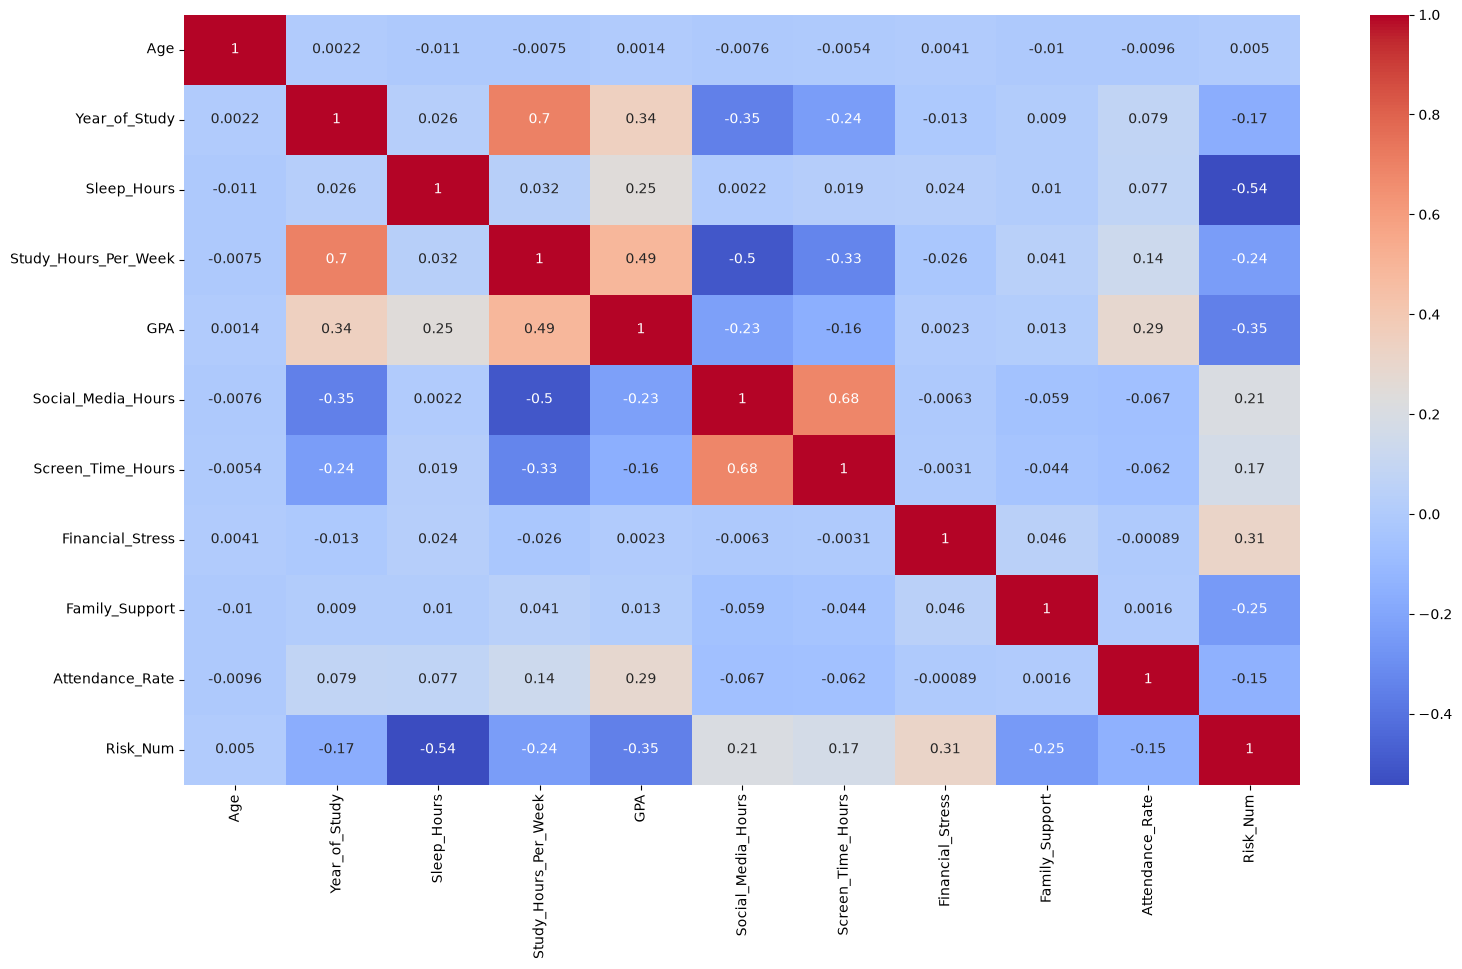

In [15]:
# Examine the correlations between the variables

df_corr = df.copy()
df_corr['Risk_Num'] = df_corr['Mental_Health_Risk'].map({'Low': 0, 'Medium': 1, 'High': 2})
plt.figure(figsize=(18, 10))
corr = df_corr.select_dtypes(include=["number"] ).corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")

##### **Feature Enginnering**
 - Drop `StudentId` Column
 - Add `Life_Style` Column Adding (Sleep_Hours + Physical Activity + Diet_Quality)

In [16]:
# Drop StudentId Column
df.drop(columns='Student_ID', inplace=True)

In [17]:
# # Add column Lifestyle

# physical_activity_mapping = {
#     "Low" : 1,
#     "Moderate" : 2,
#     "High" : 3
# }

# diet_quality_mapping = {
#     "Poor" : 1, 
#     "Average" : 2, 
#     "Good" : 3
# }
# # calculate the life style score
# raw_score = (
#     df['Sleep_Hours'] +
#     df['Physical_Activity'].map(physical_activity_mapping) +
#     df['Diet_Quality'].map(diet_quality_mapping)
# )


# df['Lifestyle_Score'] = ((raw_score - raw_score.min()) / (raw_score.max() - raw_score.min())) * 100



In [18]:
# df.groupby('Mental_Health_Risk')['Lifestyle_Score'].mean()

In [19]:
## export the csv 
df.to_csv("../data/processed/preprocessing_input.csv", index=False)